In [2]:
import pandas as pd
from sklearn.metrics import confusion_matrix

In [4]:
train = pd.read_csv("../data/raw/aps_failure_training_set.csv", skiprows = 20, na_values = "na")

X = train.drop(columns = "class")
y = (train["class"] =="pos").astype(int)

print(X.shape, y.mean().round(4))

(60000, 170) 0.0167


In [5]:
def scania_cost(y_true,y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels = [0, 1]).ravel()
    return 10 * fp + 500 * fn

print("Flag nothing:    ", scania_cost(y,[0] * len(y)))
print("Flag everything: ", scania_cost(y,[1] * len(y)))

Flag nothing:     500000
Flag everything:  590000


In [6]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.dummy import DummyClassifier

cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)

dummy = DummyClassifier(strategy = "most_frequent")
pred = cross_val_predict(dummy, X, y, cv = cv)

print("Dummy cost (5-fold CV):", scania_cost(y, pred))

Dummy cost (5-fold CV): 500000


In [7]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logreg = make_pipeline(
    SimpleImputer(strategy="median", add_indicator=True),
    StandardScaler(),
    LogisticRegression(max_iter=2000, class_weight="balanced"),
)

proba = cross_val_predict(logreg, X, y, cv=cv, method="predict_proba")[:, 1]
pred = (proba >= 0.5).astype(int)

tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
print("Logistic regression cost (5-fold CV):", scania_cost(y, pred))
print(f"Caught {tp} of {tp + fn} failures; {fp} false alarms")

Logistic regression cost (5-fold CV): 63430
Caught 905 of 1000 failures; 1593 false alarms


Logistic regression (median imputation with missing-value flags, scaling, balanced class weights) inside a Pipeline, 5-fold CV: cost 63,430 vs 500,000 for the dummy. Caught 905/1,000 failures with 1,593 false alarms. Missed failures make up 75% of the cost, so the 0.5 threshold is too high for this cost structure.

In [8]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logreg = make_pipeline(
    SimpleImputer(strategy="median", add_indicator=False),
    StandardScaler(),
    LogisticRegression(max_iter=2000, class_weight="balanced"),
)

proba = cross_val_predict(logreg, X, y, cv=cv, method="predict_proba")[:, 1]
pred = (proba >= 0.5).astype(int)

tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
print("Logistic regression cost (5-fold CV):", scania_cost(y, pred))
print(f"Caught {tp} of {tp + fn} failures; {fp} false alarms")

Logistic regression cost (5-fold CV): 65980
Caught 896 of 1000 failures; 1398 false alarms


With flags: best threshold 0.34, cost 60750
Without flags: best threshold 0.38, cost 60310


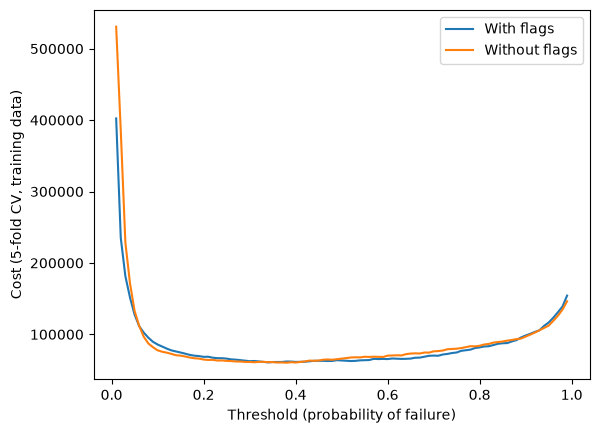

In [9]:
import numpy as np
import matplotlib.pyplot as plt

def make_logreg(flags):
    return make_pipeline(
        SimpleImputer(strategy="median", add_indicator=flags),
        StandardScaler(),
        LogisticRegression(max_iter=2000, class_weight="balanced"),
    )

proba_flags = cross_val_predict(make_logreg(True), X, y, cv=cv, method="predict_proba")[:, 1]
proba_noflags = cross_val_predict(make_logreg(False), X, y, cv=cv, method="predict_proba")[:, 1]

thresholds = np.arange(0.01, 1.00, 0.01)
for name, p in [("With flags", proba_flags), ("Without flags", proba_noflags)]:
    costs = [scania_cost(y, (p >= t).astype(int)) for t in thresholds]
    best = int(np.argmin(costs))
    print(f"{name}: best threshold {thresholds[best]:.2f}, cost {costs[best]}")
    plt.plot(thresholds, costs, label=name)

plt.xlabel("Threshold (probability of failure)")
plt.ylabel("Cost (5-fold CV, training data)")
plt.legend()
plt.show()

hreshold tuning lowered the cost from 63,430 to 60,750; the curve is flat between ~0.2 and 0.6 because balanced class weights already shift the probabilities.

Logistic regression: best threshold 0.38, cost 60310
Gradient boosting: best threshold 0.11, cost 42250


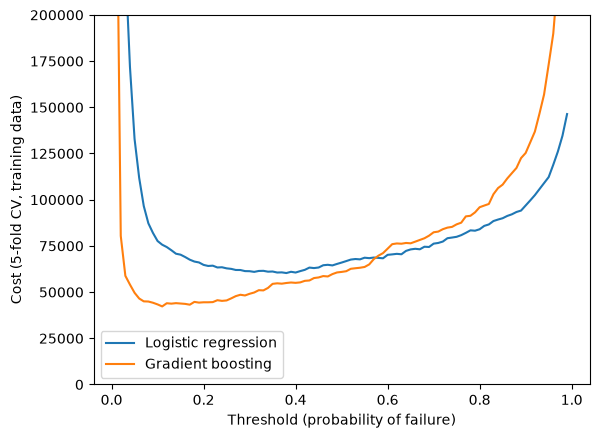

In [11]:
from sklearn.ensemble import HistGradientBoostingClassifier

hgb = HistGradientBoostingClassifier(class_weight="balanced", random_state=42)
proba_hgb = cross_val_predict(hgb, X, y, cv=cv, method="predict_proba")[:, 1]

for name, p in [("Logistic regression", proba_noflags), ("Gradient boosting", proba_hgb)]:
    costs = [scania_cost(y, (p >= t).astype(int)) for t in thresholds]
    best = int(np.argmin(costs))
    print(f"{name}: best threshold {thresholds[best]:.2f}, cost {costs[best]}")
    plt.plot(thresholds, costs, label=name)

plt.xlabel("Threshold (probability of failure)")
plt.ylabel("Cost (5-fold CV, training data)")
plt.ylim(0, 200000)
plt.legend()
plt.show()

Gradient boosting (HistGradientBoosting, native missing-value handling, balanced class weights, default settings) at a tuned threshold of 0.11: cost 42,250 vs 60,310 for logistic regression. At the default 0.5 threshold it is no better than logistic regression; the cost-based threshold is what makes the difference.

In [12]:
pred = (proba_hgb >= 0.11).astype(int)
tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
print(f"At 0.11: caught {tp} of {tp + fn} failures; {fp} false alarms; cost {10*fp + 500*fn}")
print()

for seed in [1, 2, 3]:
    cv_seed = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    p = cross_val_predict(HistGradientBoostingClassifier(class_weight="balanced", random_state=42),
                          X, y, cv=cv_seed, method="predict_proba")[:, 1]
    print(f"Fold shuffle {seed}: cost at 0.11 = {scania_cost(y, (p >= 0.11).astype(int))}")

At 0.11: caught 957 of 1000 failures; 2075 false alarms; cost 42250

Fold shuffle 1: cost at 0.11 = 44760
Fold shuffle 2: cost at 0.11 = 41520
Fold shuffle 3: cost at 0.11 = 45510


Stability check: re-running 5-fold CV with three other fold shuffles gives 41,520–45,510 at threshold 0.11, so the CV cost is about 43,500 ± 2,000. The gap to logistic regression (~60,000) is well outside this; the flags effect (440) is not.